# The Overton Paradox, Updated: Technical Appendix

Allen Downey

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/OvertonParadox/blob/main/notebooks/appendix.ipynb)

This notebook shows the whole analysis behind the articles in this series, from the survey responses to the results: how the questions were selected, how conservatism is measured, and the models of age, period, and cohort. To run the same models with your own choice of questions, try [The Overtron](https://allendowney.github.io/OvertonParadox/overtron/), which runs them in your browser. It's self-contained: every function it uses is defined here. It downloads a data excerpt (about 2.5 MB) and runs in about 15 minutes on Colab.

Where the production analysis did something the notebook can't (it started from the full GSS file, and ran longer MCMC samples), the notebook loads the saved results and checks that its own computations agree with them.

On Colab, upgrade the sampling stack before importing PyMC: Colab ships an older PyMC, and installing nutpie alone can pull in ArviZ 1.x and break the imports.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "pymc>=6" "arviz>=1.1" nutpie

In [2]:
import gzip
import json
import re
from os.path import basename, exists
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.optimize import brentq
from scipy.special import expit
from scipy.stats import norm

In [3]:
DATA_URL = "https://github.com/AllenDowney/OvertonParadox/releases/download/data-v1/"
LOCAL = "../release/data-v1/"  # staged by scripts/stage_release.sh, when running in a clone of the repo


def download(filename):
    """Download a file from the data release, unless it's already here."""
    if exists(LOCAL + filename):
        return LOCAL + filename
    if not exists(filename):
        urlretrieve(DATA_URL + filename, filename)
    return filename

## The data

The data come from the [General Social Survey](https://gss.norc.org) (GSS) cumulative file, 1972 to 2024, release 3a. The excerpt contains one row per respondent and one column for each of the 170 candidate questions described below, plus year, age, year of birth, self-identified ideology (`polviews`), and the analysis weight.

The sample excludes 2021, and in 2022 and 2024 it includes only respondents interviewed in person or by phone. In those years the GSS also used a web questionnaire, and the answers people give on the web differ systematically from the ones they give to an interviewer. The weights in 2022 and 2024 are raked to match the margins of the full sample. I'll call this the interviewer sample.

The excerpt is stored as a column store: raw little-endian columns, gzipped, described by a manifest.

In [4]:
manifest = json.load(open(download("manifest.json")))
raw = gzip.decompress(open(download("respondents.bin.gz"), "rb").read())


def decode(raw, columns):
    """The excerpt as a DataFrame; -1 in the integer columns means missing."""
    out = {}
    for col in columns:
        dtype = np.dtype(col["dtype"]).newbyteorder("<")
        a = np.frombuffer(raw, dtype=dtype, count=col["length"], offset=col["offset"])
        out[col["name"]] = np.where(a == -1, np.nan, a.astype(float)) if dtype.kind == "i" else a.astype(float)
    return pd.DataFrame(out)


gss = decode(raw, manifest["columns"])
gss["year"] = gss["year"].astype(int)
gss.shape

(68005, 195)

`questions.json` has the metadata for each question: its description, wording, and value labels, and, for checking, the results of each step of the selection as the production code computed them.

In [5]:
table = json.load(open(download("questions.json")))
meta = pd.DataFrame(table["questions"]).T
len(meta)

188

Self-identified ideology is the 7-point `polviews` scale. I group it into liberal (1–3), moderate (4), and conservative (5–7).

In [6]:
def polviews3(x):
    return np.select([x <= 3, x == 4, x >= 5], ["Liberal", "Moderate", "Conservative"], None)


gss["polviews3"] = pd.Series(polviews3(gss["polviews"]), index=gss.index).where(gss["polviews"].notna())
gss["decade"] = gss["year"] // 10 * 10
gss.groupby("decade")["polviews3"].value_counts(normalize=True).unstack().round(2)

polviews3,Conservative,Liberal,Moderate
decade,,,
1970,0.31,0.29,0.39
1980,0.34,0.27,0.39
1990,0.36,0.27,0.37
2000,0.34,0.27,0.39
2010,0.33,0.28,0.38
2020,0.34,0.28,0.37


## Selecting the questions

The articles describe the selection in nine steps. Steps 1 and 2 started from the full GSS file, which has 6,943 variables; the excerpt contains only the 170 questions that came out of them, so for those steps I describe what was done. Steps 3 to 9 run here.

### Steps 1 and 2: gates and scope

1. **Gates.** Keep variables asked in at least 8 survey years (counting years with at least 100 respondents who also answered `polviews`), spanning at least 15 years, with 2 to 7 distinct answers, and not administrative. Run on the interviewer sample, 429 variables pass.

2. **Scope.** Keep questions that ask for an opinion about a public issue or a social norm. Exclude demographics, behaviors and experiences, personal circumstances, knowledge, religious belief and practice, and party identification and vote. 170 questions remain.

These are the 170 candidates:

In [7]:
candidates = [v for v in meta.index if meta.loc[v, "rank"] is not None and not pd.isna(meta.loc[v, "rank"])]
len(candidates)

170

### Step 3: identify the conservative answers

For each question, the conservative answers are the ones conservatives choose more often than liberals. Specifically:

- for each answer and each survey year, compute the weighted percentage of conservatives who chose it, minus the percentage of liberals;
- average those differences over the years, weighted by the number of respondents;
- split the ordered answer scale at the point where the cumulative difference is largest; the side conservatives choose more is the conservative side.

Volunteered answers that aren't positions on the question ("other", "depends", "neither") never count as conservative. For two questions, the answer codes aren't in scale order, so the order is given explicitly. And for the 15 questions used in *Probably Overthinking It*, I kept the codings used in the book.

In [8]:
NOT_A_POSITION = ["other", "depends", "depends on age", "neither", "wdnt belong", "wouldnt vote",
                  "r pays no income tax (vol.)"]
SCALE_ORDER = {
    "divlaw": [1, 3, 2],  # easier, stay as is, more difficult
    "courts": [1, 3, 2],  # too harshly, about right, not harshly enough
}


def response_differences(gss, varname):
    """Conservative minus liberal percentage choosing each answer, averaged over years."""
    data = gss[["year", "polviews3", "weight", varname]].dropna()
    data = data[data["polviews3"].isin(["Conservative", "Liberal"])]
    diffs, counts = [], []
    for year, group in data.groupby("year"):
        shares = group.pivot_table(index=varname, columns="polviews3", values="weight", aggfunc="sum", fill_value=0)
        if not {"Conservative", "Liberal"} <= set(shares.columns):
            continue
        shares = shares / shares.sum()
        diffs.append((shares["Conservative"] - shares["Liberal"]) * 100)
        counts.append(len(group))
    table = pd.concat(diffs, axis=1).fillna(0)
    return (table * counts).sum(axis=1) / sum(counts)


def best_cut(positions, order):
    """The contiguous split of an ordered scale that best separates the groups."""
    cum = positions.reindex(order).cumsum().iloc[:-1]
    k = cum.abs().values.argmax()
    low, high = list(order[: k + 1]), list(order[k + 1 :])
    return (low, cum.iloc[k]) if cum.iloc[k] > 0 else (high, -cum.iloc[k])


def code_question(gss, varname):
    labels = {float(code): label for code, label in meta.loc[varname, "value_labels"].items()}
    diff = response_differences(gss, varname)
    positions = diff.drop([v for v in diff.index if labels.get(v, "").lower() in NOT_A_POSITION])
    order = [float(v) for v in SCALE_ORDER.get(varname, sorted(positions.index))]
    return best_cut(positions, order)

For example, here are the differences for the question about the death penalty, `cappun` ("Do you favor or oppose the death penalty for persons convicted of murder?"):

In [9]:
response_differences(gss, "cappun").round(1)

cappun
1.0    20.0
2.0   -20.0
dtype: float64

Averaged over the years, conservatives are 20 points more likely than liberals to say "favor" (1), so that's the conservative answer.

In [10]:
book_codes = {v: [float(c) for c in codes] for v, codes in table["book_codes"].items()}
codes, separation = {}, {}
for v in candidates:
    side, size = code_question(gss, v)
    codes[v] = book_codes.get(v, sorted(side))
    separation[v] = size

Check: the codings agree with the production code's.

In [11]:
saved = {v: [float(c) for c in meta.loc[v, "conservative"]] for v in candidates}
assert all(codes[v] == saved[v] for v in candidates)
assert max(abs(separation[v] - meta.loc[v, "separation"]) for v in candidates) < 1e-6

With the codings, each answer becomes 1 (conservative), 0 (not conservative), or missing (not asked, or no answer).

In [12]:
def make_coded(gss, codes):
    """1 for a conservative answer, 0 for another answer, NaN if not answered."""
    return pd.DataFrame({v: gss[v].isin(cs).astype(float).where(gss[v].notna()) for v, cs in codes.items()})


coded = make_coded(gss, codes)

### Step 4: measure how well each question separates conservatives and liberals

For each question, a weighted logistic regression of the coded answer on survey year, year of birth, and `polviews` (all linear). The coefficient of `polviews` measures how strongly the conservative answer is associated with self-identified ideology, controlling for year and cohort. It's used only to choose among questions on the same topic (step 7); there's no cutoff.

In [13]:
w_mean1 = gss["weight"] / gss["weight"].mean()


def polviews_coefficient(v):
    data = pd.DataFrame(dict(y=coded[v], year=gss["year"], cohort=gss["cohort"], polviews=gss["polviews"],
                             w=w_mean1)).dropna()
    model = smf.glm("y ~ year + cohort + polviews", data=data, family=sm.families.Binomial(),
                    freq_weights=data["w"])
    return model.fit().params["polviews"]


param = pd.Series({v: polviews_coefficient(v) for v in candidates}).sort_values(ascending=False)
param.head(10).round(3)

homosex     0.442
helppoor    0.390
helpnot     0.375
pillok      0.348
sexeduc     0.345
helpsick    0.345
wrkwayup    0.338
natarmsy    0.331
abany       0.331
goveqinc    0.329
dtype: float64

Check: the coefficients agree with the production code's.

In [14]:
assert np.allclose(param, meta.loc[param.index, "polviews_param"].astype(float), atol=1e-6)

### Step 5: coverage

A question has to be asked in at least half of the 32 survey years in the interviewer sample, counting years with at least 100 respondents who answered it and `polviews`.

In [15]:
MIN_WAVES = 16

answered_with_polviews = coded.notna() & gss["polviews"].notna().values[:, None]
waves = (answered_with_polviews.groupby(gss["year"]).sum() >= 100).sum()
assert (waves[candidates] == meta.loc[candidates, "waves"].astype(int)).all()
coverage_ok = waves >= MIN_WAVES
coverage_ok.sum()

np.int64(121)

### Step 6: stability

For each question and decade, the **gap** is the weighted percentage of conservatives who gave the conservative answer, minus the percentage of liberals, with a 90% interval based on Kish's effective sample size. Decades with fewer than 200 liberal and conservative respondents are left out.

A question is excluded if the gap **reverses**: in one decade, conservatives are credibly more likely to give the conservative answer, by at least 5 percentage points, and in another decade liberals are credibly more likely, by at least 5 points. ("Credibly" means the 90% interval excludes 0.)

A gap that shrinks is allowed. When nearly everyone gives the same answer, the gap between any two groups has to shrink, even if the question means the same thing.

In [16]:
REVERSAL_POINTS = 5
MIN_RESPONDENTS = 200
Z90 = norm.ppf(0.95)


def weighted_share(y, w):
    """Weighted mean and its standard error, using Kish's effective sample size."""
    p = np.average(y, weights=w)
    n_eff = w.sum() ** 2 / (w**2).sum()
    return p, np.sqrt(p * (1 - p) / n_eff)


def decade_gaps(v):
    df = pd.DataFrame(dict(y=coded[v], p=gss["polviews3"], w=gss["weight"], decade=gss["decade"])).dropna()
    df = df[df["p"].isin(["Liberal", "Conservative"])]
    rows = []
    for d, group in df.groupby("decade"):
        con, lib = group[group["p"] == "Conservative"], group[group["p"] == "Liberal"]
        if len(group) < MIN_RESPONDENTS or len(con) == 0 or len(lib) == 0:
            continue
        pc, sc = weighted_share(con["y"].values, con["w"].values)
        pl, sl = weighted_share(lib["y"].values, lib["w"].values)
        gap, se = (pc - pl) * 100, np.hypot(sc, sl) * 100
        rows.append(dict(decade=d, gap=gap, lo=gap - Z90 * se, hi=gap + Z90 * se))
    return pd.DataFrame(rows)


def reverses(gaps):
    con_ahead = (gaps["lo"] > 0) & (gaps["gap"] >= REVERSAL_POINTS)
    lib_ahead = (gaps["hi"] < 0) & (gaps["gap"] <= -REVERSAL_POINTS)
    return bool(con_ahead.any() and lib_ahead.any())


gaps = {v: decade_gaps(v) for v in candidates}
reversal = pd.Series({v: reverses(g) for v, g in gaps.items()})
reversal[reversal].index.tolist()

['confed']

Only one question reverses: confidence in the executive branch, whose gap follows the party in the White House. It's also excluded by step 8.

In [17]:
gaps["confed"].round(1)

,decade,gap,lo,hi
0,1970,-3.7,-6.3,-1.1
1,1980,-10.4,-12.7,-8.0
2,1990,9.3,6.8,11.8
3,2000,-9.9,-12.8,-7.0
4,2010,14.7,11.8,17.5
5,2020,33.6,26.7,40.6


Check: the gaps agree with the production code's (which reports them rounded to whole points).

In [18]:
def gap_string(g):
    return " ".join(f"{d}s:{x:+.0f}" for d, x in zip(g["decade"], g["gap"]))


assert all(gap_string(gaps[v]) == meta.loc[v, "gap_by_decade"] for v in candidates)

### Step 7: no duplicates

Some questions were asked with two different wordings on different versions of the survey (the spending questions whose names end in `y`); I keep the original wording. And when several questions cover the same topic, like the seven versions of the abortion question, I keep the one with the largest `polviews` coefficient (step 4). The topics were assigned by hand, before any results; the `topic` field has them.

In [19]:
meta.loc[candidates].groupby("topic").size().loc[lambda s: s > 1]

topic
abortion                               7
affirmative action                     2
causes of racial inequality            4
child-rearing values                   5
civil liberties: Muslim clergy         3
civil liberties: anti-religionist      3
civil liberties: communist             3
civil liberties: homosexual            3
civil liberties: militarist            3
civil liberties: racist                3
end of life                            2
government help for Black Americans    3
health care                            3
income inequality                      2
police use of force                    5
racial stereotypes                     6
social trust                           3
suicide                                3
teen sexuality                         2
welfare and the poor                   3
women in politics                      2
working mothers                        2
dtype: int64

### Step 8: no confidence questions

The 13 questions about confidence in institutions are left out, because confidence in an institution can reflect approval of its current decisions, perceived legitimacy, trust in expertise, or partisan alignment, rather than a position on an issue. This rule was adopted after seeing results that included them; the articles say so, and report the results with them as a sensitivity analysis.

In [20]:
CONFIDENCE = r"^con(press|labor|clerg|educ|bus|army|sci|tv|finan|fed|legis|judge|medic)$"
confidence = pd.Series({v: bool(re.match(CONFIDENCE, v)) for v in candidates})
confidence.sum()

np.int64(13)

Applying steps 5 to 8:

In [21]:
def select(drop=()):
    """Candidates in rank order that pass coverage, stability, wording, and confidence, one per topic."""
    keep = [v for v in param.index
            if coverage_ok[v] and not reversal[v] and not confidence[v]
            and not (v.startswith("nat") and v.endswith("y")) and v not in drop]
    topics = meta.loc[keep, "topic"]
    return list(topics[~topics.duplicated()].index)


before_drift = select()
len(before_drift)

55

### Step 9: check for drift

A question drifts if its connection to conservatism changes over time. To check, for each question:

- estimate each respondent's conservatism from the *other* questions (a leave-one-out score; the measurement model is described in the next section);
- fit a weighted logistic regression of the answer to this question on that score and one indicator per decade, with the decade effects measured relative to their average;
- list the question for review if some decade's effect is credibly different from 0 and at least 0.5 on the logit scale (for a question that half of people answer conservatively, that's about 12 percentage points).

The listed questions were reviewed one at a time, and each decision recorded. Most were questions where opinion moved faster or slower than on the others, which is real change, so they were kept. The functions this step uses are defined in the next section, so the drift check runs there.

## Measuring conservatism

Respondents in different years answered different subsets of the questions: questions were added and dropped over the decades, and the GSS asks many of them on only some versions of the survey. So a simple count of conservative answers isn't comparable from one respondent to another. Instead, I use a one-parameter item response (Rasch) model:

- each respondent has a latent conservatism, $\theta$;
- each question has a difficulty, $d$;
- the probability of a conservative answer is $\mathrm{expit}(\theta - d)$.

A question with a high difficulty is one that only the most conservative respondents answer conservatively.

The latent conservatism is represented on a grid of 21 values from −6 to 6, with a wide normal prior (standard deviation 4).

In [22]:
XS = np.linspace(-6, 6, 21)
PRIOR = norm.pdf(XS, 0, 4)
PRIOR /= PRIOR.sum()
MIN_ANSWERED = 5


def log_likelihoods(a, d, xs=XS):
    """Each question's log likelihood on the grid: shape (questions, respondents, grid).

    a: array of 1/0/NaN answers (respondents x questions); d: difficulties
    """
    P = expit(xs[None, :] - d[:, None])
    out = np.zeros((a.shape[1], a.shape[0], len(xs)))
    for j in range(a.shape[1]):
        col = a[:, j, None]
        out[j] = np.where(col == 1, np.log(P[j]), np.where(col == 0, np.log(1 - P[j]), 0))
    return out


def grid_posterior(a, d, prior=PRIOR, xs=XS):
    """Each respondent's posterior on the grid."""
    loglike = log_likelihoods(a, d, xs).sum(axis=0)
    posterior = np.exp(loglike - loglike.max(axis=1, keepdims=True)) * prior
    return posterior / posterior.sum(axis=1, keepdims=True)

### Difficulties

The difficulties are estimated once, from all years combined, by weighted marginal maximum likelihood, using the EM algorithm of Bock and Aitkin:

- E step: each respondent's posterior on the grid, given the current difficulties;
- M step: for each question, the difficulty at which the weighted expected share of conservative answers, among the respondents who were asked, equals the observed weighted share.

The calibration uses respondents who answered at least 5 of the questions. It stops when no difficulty changes by more than 0.0001, or after 100 iterations.

In [23]:
def em_difficulties(coded, weights, tol=1e-4, max_iter=100):
    a = coded.values
    w = np.asarray(weights, dtype=float)
    asked = ~np.isnan(a)
    share = np.nansum(a * w[:, None], axis=0) / (asked * w[:, None]).sum(axis=0)
    d = -np.log(share / (1 - share))  # start: minus the logit of the prevalence
    for _ in range(max_iter):
        posterior = grid_posterior(a, d)
        new = d.copy()
        for j in range(a.shape[1]):
            mass = (w[asked[:, j], None] * posterior[asked[:, j]]).sum(axis=0)
            target = (w[asked[:, j]] * a[asked[:, j], j]).sum()
            new[j] = brentq(lambda dj: (mass * expit(XS - dj)).sum() - target, -10, 10)
        change = np.abs(new - d).max()
        d = new
        if change < tol:
            break
    return pd.Series(d, coded.columns)


def calibrate(names):
    """EM difficulties for a set of questions, from respondents who answered at least MIN_ANSWERED."""
    sub = coded[names]
    keep = (sub.notna().sum(axis=1) >= MIN_ANSWERED).values
    return em_difficulties(sub[keep], gss.loc[keep, "weight"])

### Step 9, continued: the drift check

In [24]:
DRIFT_THRESHOLD = 0.5  # logits


def drift(names, only=None):
    """Decade effects for each question, controlling for its leave-one-out score."""
    d = calibrate(names)
    a = coded[names].values
    ll = log_likelihoods(a, d.values)
    total = ll.sum(axis=0)
    answered = ~np.isnan(a)
    n_answered = answered.sum(axis=1)
    rows = []
    for j, v in enumerate(names):
        if only and v not in only:
            continue
        keep = answered[:, j] & (n_answered - 1 >= MIN_ANSWERED)
        loo = total[keep] - ll[j, keep]
        post = np.exp(loo - loo.max(axis=1, keepdims=True)) * PRIOR
        score = (post / post.sum(axis=1, keepdims=True)) @ XS
        y, w, decade = a[keep, j], gss["weight"].values[keep], gss["decade"].values[keep]
        counts = pd.Series(decade).value_counts()
        ok = np.isin(decade, counts.index[counts >= MIN_RESPONDENTS])
        decades = np.sort(np.unique(decade[ok]))
        X = np.column_stack([score[ok]] + [(decade[ok] == k).astype(float) for k in decades])
        res = sm.GLM(y[ok], X, family=sm.families.Binomial(), var_weights=w[ok] / w[ok].mean()).fit(cov_type="HC1")
        k = len(decades)
        C = np.zeros((k, k + 1))
        C[:, 1:] = np.eye(k) - 1 / k  # each decade relative to the mean of the decades
        effect = C @ res.params
        se = np.sqrt(np.diag(C @ res.cov_params() @ C.T))
        listed = ((np.abs(effect) - Z90 * se > 0) & (np.abs(effect) >= DRIFT_THRESHOLD)).any()
        rows.append(dict(variable=v, description=meta.loc[v, "description"], slope=res.params[0], listed=listed,
                         **{f"{dec}s": e for dec, e in zip(decades, effect)}))
    return pd.DataFrame(rows).set_index("variable")


drift_table = drift(before_drift)
listed = drift_table[drift_table["listed"]]
len(listed)

14

These are the listed questions, with their decade effects on the logit scale and the slope on the leave-one-out score:

In [25]:
listed.drop(columns="listed").round(2)

,description,slope,1970s,1980s,1990s,2000s,2010s,2020s
variable,,,,,,,,
homosex,homosexual sex relations,1.60,0.65,0.84,0.36,-0.06,-0.78,-1.01
grass,should marijuana be made legal,1.05,0.28,0.76,0.67,0.20,-0.64,-1.26
xmarsex,sex with person other than spouse,1.02,-0.71,-0.39,0.11,0.38,0.29,0.32
fefam,"better for man to work, woman tend home",1.25,0.65,0.00,-0.16,-0.05,-0.31,-0.12
divlaw,divorce laws,0.85,-0.15,0.24,0.34,0.32,-0.06,-0.68
courts,courts dealing with criminals,0.66,0.24,0.64,0.52,-0.29,-0.56,-0.55
colhomo,allow homosexual to teach,1.63,0.56,0.41,0.01,-0.25,-0.74,NaN
fepol,women not suited for politics,0.91,0.67,0.30,-0.20,-0.02,-0.31,-0.43
racopen,vote on open housing law,0.71,1.00,0.43,-0.01,-0.18,-0.43,-0.82


Each was reviewed with its wording, coded answer, and decade effects. Twelve were kept: the departures look like opinion moving faster or slower than on the other questions, not a change in what the answer means. Two were excluded:

- `librac`, removing a racist's book from a public library: removing such a book is no longer a distinctively conservative position.
- `natspac`, spending on the space program: besides the drift, its answer is slightly *negatively* related to the other questions (the slope on the leave-one-out score is below 0).

With `librac` out, the topic rule (step 7) gives its place to `colrac`, allowing a racist to teach in a college. Its drift check shows the same pattern as `librac`, so it was excluded too, along with the rest of the topic (`spkrac` isn't brought in). There were no further rounds.

In [26]:
drift(select(drop=["librac", "natspac"]), only=["colrac"]).drop(columns="listed").round(2)

,description,slope,1970s,1980s,1990s,2000s,2010s,2020s
variable,,,,,,,,
colrac,allow racist to teach,0.66,-0.25,-0.16,-0.13,-0.13,0.07,0.6


In [27]:
DRIFT_EXCLUDED = ["librac", "natspac", "colrac", "spkrac"]
primary = select(drop=DRIFT_EXCLUDED)
len(primary)

53

Check: this is the selection the articles use.

In [28]:
assert sorted(primary) == sorted(table["presets"]["primary"])

These are the 53 primary questions, in rank order:

In [29]:
meta.loc[primary, ["description", "first", "last", "waves"]]

,description,first,last,waves
homosex,homosexual sex relations,1974,2024,28
helppoor,should govt improve standard of living?,1975,2024,25
helpnot,should govt do more or less?,1975,2024,25
pillok,birth control to teenagers 14-16,1986,2024,21
sexeduc,sex education in public schools,1974,2024,27
helpsick,should govt help pay for medical care?,1975,2024,25
abany,abortion if woman wants for any reason,1977,2024,28
grass,should marijuana be made legal,1975,2024,28
eqwlth,should govt reduce income differences,1978,2024,26
premarsx,sex before marriage,1974,2024,28


So, precisely, the measure is how closely someone's answers match a fixed collection of positions that have been associated with self-identified conservatism over the last 50 years.

### Connectivity

Scores of people surveyed decades apart are comparable only through the questions asked in both periods. This table shows how many of the primary questions were asked in each pair of decades.

In [30]:
asked = answered_with_polviews[primary].groupby(gss["year"]).sum() >= 100
by_decade = asked.groupby(asked.index // 10 * 10).any()
shared = by_decade.astype(int) @ by_decade.T.astype(int)
shared.index = shared.columns = [f"{d}s" for d in by_decade.index]
shared

,1970s,1980s,1990s,2000s,2010s,2020s
1970s,44,44,44,41,40,37
1980s,44,51,51,48,47,44
1990s,44,51,53,50,49,46
2000s,41,48,50,50,49,46
2010s,40,47,49,49,49,46
2020s,37,44,46,46,46,46


In [31]:
asked.sum(axis=1).rename("questions asked").to_frame().T

year,1972,1973,1974,1975,1976,1977,1978,1980,1982,1983,...,2004,2006,2008,2010,2012,2014,2016,2018,2022,2024
questions asked,0,0,25,29,26,33,25,26,30,31,...,48,48,49,49,48,48,48,48,46,43


### Scores

With the difficulties calibrated on the primary questions, each respondent's score is the posterior mean of the number of the 53 questions they would answer conservatively if they were asked all of them, expressed as a percentage: "percent conservative responses". The analysis uses respondents who answered at least 5 of the questions and whose age and year of birth are known.

In [32]:
d_primary = calibrate(primary)
assert np.allclose(d_primary, pd.Series(table["preset_settings"]["primary"]["difficulties"])[primary], atol=1e-9)


def percent_conservative(names, d):
    """Posterior mean percent conservative responses, for every respondent."""
    posterior = grid_posterior(coded[names].values, d[names].values)
    expected = expit(XS[None, :] - d[names].values[:, None]).mean(axis=0) * 100  # at each grid point
    return posterior @ expected


answered_primary = coded[primary].notna().sum(axis=1)
keep = (answered_primary >= MIN_ANSWERED) & gss["cohort"].notna() & gss["age"].notna()
df = gss.loc[keep, ["year", "age", "cohort", "polviews", "polviews3", "weight"]].copy()
df["y"] = percent_conservative(primary, d_primary)[keep.values] / 100  # the models work with proportions
len(df)

64632

Weighted average by year:

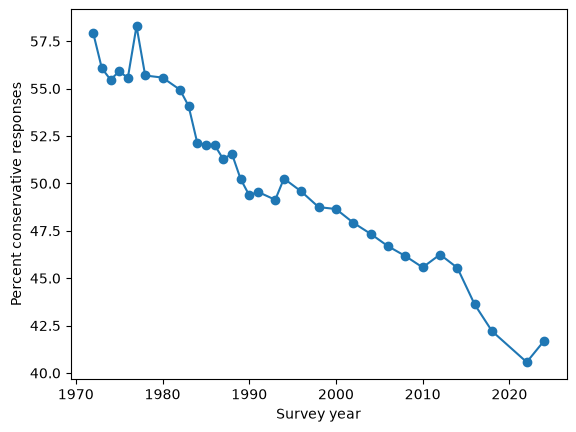

In [33]:
yearly = df.groupby("year").apply(lambda g: np.average(g["y"], weights=g["weight"]) * 100)
yearly.plot(xlabel="Survey year", ylabel="Percent conservative responses", style="o-");

Check: the scores agree with the production code's, for a sample of respondents, and so do the yearly means.

In [34]:
fixture = json.load(open(download("primary_fixture.json")))
sample = pd.DataFrame(fixture["sample"])
mine = gss.loc[keep, ["year", "id"]].assign(y=df["y"].values).merge(sample, on=["year", "id"], suffixes=("", "_saved"))
assert len(mine) == len(sample) and np.allclose(mine["y"], mine["y_saved"], atol=1e-9)
saved_yearly = pd.Series(fixture["yearly_mean_y"]).rename(index=int) * 100
assert np.allclose(yearly, saved_yearly.loc[yearly.index], atol=1e-9)

## Models of age, period, and cohort

The models work with the weighted mean score in groups of respondents (cells): by survey year, by age, or by year of birth × survey year. Each cell has a weighted mean, a weighted variance, and Kish's effective sample size.

In [35]:
def weighted_cells(df, keys):
    def summarize(g):
        w, y = g["weight"].values, g["y"].values
        mean = np.average(y, weights=w)
        return pd.Series(dict(p_weighted=mean, var_weighted=np.average((y - mean) ** 2, weights=w), n=len(g),
                              n_eff=w.sum() ** 2 / (w**2).sum()))

    return df.groupby(keys).apply(summarize).reset_index()

### The random walk prior

The trends over time, age, and year of birth are smooth curves with a second-order random walk (RW2) prior: each step's change in slope is normal with standard deviation $\sigma$, and the curve is centered at 0 so it doesn't compete with the intercept. Sampling the RW2 directly (as a double cumulative sum of innovations) is slow, because the innovations are strongly correlated in the posterior. The same prior can be written in other coordinates: the eigenvectors of the centered RW2 covariance, with the linear trend split out as a separate parameter. The two forms define the same model; the second samples several times faster. The derivation is in [a separate note](https://github.com/AllenDowney/OvertonParadox/blob/main/jb/rw2_reparameterization.md).

In [36]:
import pymc as pm


def rw2_trend_basis(n):
    """Eigenbasis of the centered RW2 prior, with the linear ramp split out."""
    L = np.zeros((n, n - 2))
    for k in range(2, n):
        L[k, : k - 1] = np.arange(k - 1, 0, -1)
    P = np.eye(n) - 1 / n
    lam, U = np.linalg.eigh(P @ L @ L.T @ P)
    keep = lam > 1e-9 * lam.max()
    M = U[:, keep] * np.sqrt(lam[keep])
    r = P @ np.arange(n, dtype=float)
    a = M.T @ r / (r @ r)
    return M - np.outer(r, a), r, a


def rw2(name, n, sigma, slope_init_scale, dims):
    """Centered RW2 with a free initial slope, in the trend form."""
    M_perp, r, a = rw2_trend_basis(n)
    w = pm.Normal(f"{name}_w", 0.0, 1.0, shape=n - 2)
    beta = pm.Flat(f"{name}_trend")
    v0 = beta - sigma * pm.math.dot(a, w)
    pm.Potential(f"{name}_slope_init_prior", pm.logp(pm.Normal.dist(0.0, slope_init_scale), v0))
    return pm.Deterministic(name, sigma * pm.math.dot(M_perp, w) + beta * r, dims=dims)

### The models

- **Period** (and **age**): a smooth curve over survey years (or ages), plus independent noise for each year, on the logit scale, fit to the cell means. This model is used for each group of self-identified ideology, and for each decade of birth.
- **Period–cohort**: a smooth curve over years of birth (the cohort component) plus a smooth curve over survey years (the period component), plus year noise, fit to the cells of year of birth × survey year. The period component is the change within cohorts: how the beliefs of people born in the same year change over time. Following a birth cohort, age and period move together, so this change combines the effects of aging and of the times; the model doesn't try to separate them.

The prior scales are the same as in *You Would Choose Now*.

In [37]:
PERIOD_SETTINGS = dict(sigma_t_scale=0.125, slope_init_scale=0.2, sigma_short_scale=0.5)
COHORT_SETTINGS = dict(sigma_c_scale=0.125, sigma_t_scale=0.125, slope_init_scale=0.2, sigma_short_scale=0.2,
                       sigma_resid_scale=0.5)


def series_model(cells, index, grid, s=PERIOD_SETTINGS):
    idx = cells[index].map({v: i for i, v in enumerate(grid)}).values
    se = np.sqrt(np.maximum(cells["var_weighted"].values, 1e-4) / np.maximum(cells["n_eff"].values, 1.0))
    with pm.Model(coords={"grid": grid}) as m:
        alpha = pm.Normal("alpha", 0.0, 1.0)
        sigma_t = pm.Exponential("sigma_t", 1.0 / s["sigma_t_scale"])
        trend = rw2("trend", len(grid), sigma_t, s["slope_init_scale"], dims="grid")
        eta = pm.Deterministic("eta", alpha + trend, dims="grid")
        pm.Deterministic("mu", pm.math.sigmoid(eta), dims="grid")
        sigma_short = pm.HalfNormal("sigma_short", s["sigma_short_scale"])
        epsilon_z = pm.ZeroSumNormal("epsilon_z", sigma=1.0, dims="grid")
        epsilon = pm.Deterministic("epsilon", sigma_short * epsilon_z, dims="grid")
        pm.Normal("y_mean", mu=pm.math.sigmoid(eta[idx] + epsilon[idx]), sigma=se, observed=cells["p_weighted"].values)
    return m


def period_cohort_model(cells, years, cohorts, s=COHORT_SETTINGS):
    t = cells["year"].map({v: i for i, v in enumerate(years)}).values
    c = cells["cohort"].map({v: i for i, v in enumerate(cohorts)}).values
    with pm.Model(coords={"year": years, "cohort_grid": cohorts}) as m:
        alpha = pm.Normal("alpha", 0.0, 1.0)
        sigma_c = pm.Exponential("sigma_c", 1.0 / s["sigma_c_scale"])
        cohort = rw2("cohort", len(cohorts), sigma_c, s["slope_init_scale"], dims="cohort_grid")
        sigma_t = pm.Exponential("sigma_t", 1.0 / s["sigma_t_scale"])
        period = rw2("period", len(years), sigma_t, s["slope_init_scale"], dims="year")
        sigma_short = pm.Exponential("sigma_short", 1.0 / s["sigma_short_scale"])
        epsilon_z = pm.ZeroSumNormal("epsilon_z", sigma=1.0, dims="year")
        epsilon = pm.Deterministic("epsilon", sigma_short * epsilon_z, dims="year")
        p_obs = pm.math.sigmoid(alpha + cohort[c] + period[t] + epsilon[t])
        sigma_resid = pm.HalfNormal("sigma_resid", s["sigma_resid_scale"], dims="year")
        pm.Normal("y_mean", mu=p_obs, sigma=sigma_resid[t] / np.sqrt(cells["n_eff"].values),
                  observed=cells["p_weighted"].values)
    return m

### Sampling

The production fits used 4 chains with 4,000 tuning steps and 6,000 draws each. To keep this notebook quick, it uses 2 chains with 1,000 tuning steps and 1,000 draws, and then compares the results with the production fits. It uses the nutpie sampler if it's installed, and PyMC's default sampler otherwise.

In [38]:
try:
    import nutpie  # noqa: F401
    SAMPLER = "nutpie"
except ImportError:
    SAMPLER = "pymc"


def sample(m, target_accept, seed=17):
    with m:
        return pm.sample(tune=1000, draws=1000, chains=2, target_accept=target_accept, random_seed=seed,
                         nuts_sampler=SAMPLER, progressbar=False)


def draws_of(trace, name):
    values = trace.posterior[name].values
    return values.reshape(-1, *values.shape[2:])


def interval(x, axis=0):
    return np.mean(x, axis=axis), np.quantile(x, 0.05, axis=axis), np.quantile(x, 0.95, axis=axis)

A series fit returns the curve (on the percent scale) and its linear slope per decade, over the values that have data.

In [39]:
def fit_series(sub, index, target_accept=0.99):
    grid = list(range(int(sub[index].min()), int(sub[index].max()) + 1))
    cells = weighted_cells(sub.assign(**{index: sub[index].astype(int)}), [index])
    trace = sample(series_model(cells, index, grid), target_accept)
    mu = draws_of(trace, "mu") * 100
    x = np.asarray(grid, float)
    observed = np.isin(x, cells[index].values)
    xs = x[observed] - x[observed].mean()
    slope = (mu[:, observed] - mu[:, observed].mean(axis=1, keepdims=True)) @ xs / (xs @ xs) * 10
    mean, lo, hi = interval(mu)
    curve = pd.DataFrame({index: grid, "mean": mean, "lo90": lo, "hi90": hi})
    return curve, dict(zip(["slope_per_decade", "slope_lo90", "slope_hi90"], map(float, interval(slope)))), trace

The period–cohort fit returns the two components and the decomposition of the total change:

- the **period component**, standardized to the mix of birth years in the whole sample, and its linear slope per decade: the within-cohort change, the first metric in the articles;
- the **cohort component**, at the average period;
- the **decomposition** of the change from the first survey year to the last into generational replacement (the mix of birth years changes, period held fixed) and changing minds (the period changes, mix held fixed), averaging the two orders of the decomposition.

In [40]:
def fit_period_cohort(sub, target_accept=0.99):
    sub = sub.assign(cohort=sub["cohort"].astype(int))
    years = list(range(sub["year"].min(), sub["year"].max() + 1))
    cohorts = list(range(sub["cohort"].min(), sub["cohort"].max() + 1))
    cells = weighted_cells(sub, ["cohort", "year"])
    trace = sample(period_cohort_model(cells, years, cohorts), target_accept)
    alpha = draws_of(trace, "alpha")[:, None]
    cohort, period = draws_of(trace, "cohort"), draws_of(trace, "period")

    survey_years = sorted(sub["year"].unique())
    ti = {y: years.index(y) for y in survey_years}
    comp = sub.groupby(["year", "cohort"])["weight"].sum().unstack(fill_value=0).reindex(columns=cohorts, fill_value=0)
    comp = comp.div(comp.sum(axis=1), axis=0).loc[survey_years].values

    def level(mix, t):
        """Mean percent with cohort mix `mix` and the period at index t."""
        return (expit(alpha + cohort + period[:, t, None]) * mix).sum(axis=1) * 100

    y0, y1 = survey_years[0], survey_years[-1]
    p0, p1 = level(comp[0], ti[y0]), level(comp[-1], ti[y1])
    fix_cohort, fix_period = level(comp[0], ti[y1]), level(comp[-1], ti[y0])
    total = p1 - p0
    replacement = 0.5 * ((fix_period - p0) + (total - (fix_cohort - p0)))
    summary = {}
    for label, x in [("total_change", total), ("generational_replacement", replacement),
                     ("changing_minds", total - replacement)]:
        summary.update(dict(zip([label, f"{label}_lo90", f"{label}_hi90"], map(float, interval(x)))))

    pooled = sub.groupby("cohort")["weight"].sum().reindex(cohorts, fill_value=0).values
    std_period = np.stack([level(pooled / pooled.sum(), j) for j in range(len(years))], axis=1)
    x = np.array(survey_years, float) - np.mean(survey_years)
    sp = std_period[:, [ti[y] for y in survey_years]]
    slope = (sp - sp.mean(axis=1, keepdims=True)) @ x / (x @ x) * 10
    summary.update(zip(["period_slope_per_decade", "period_slope_lo90", "period_slope_hi90"],
                       map(float, interval(slope))))

    mean, lo, hi = interval(std_period)
    period_df = pd.DataFrame(dict(year=years, mean=mean, lo90=lo, hi90=hi))
    mean, lo, hi = interval(expit(alpha + cohort + period.mean(axis=1, keepdims=True)) * 100)
    cohort_df = pd.DataFrame(dict(cohort=cohorts, mean=mean, lo90=lo, hi90=hi))
    return period_df, cohort_df, summary, trace

The production results, for comparison:

In [41]:
saved = pd.read_csv(download("apc_summary.csv")).set_index("run")

## Results

### Older people are more conservative

Within each decade of surveys, the age model shows how conservatism varies with age.

In [42]:
age_fits = {}
for start in range(1970, 2030, 10):
    window = df[df["year"].between(start, start + 9)]
    age_fits[start] = fit_series(window.assign(age=window["age"].astype(int)), "age")

NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


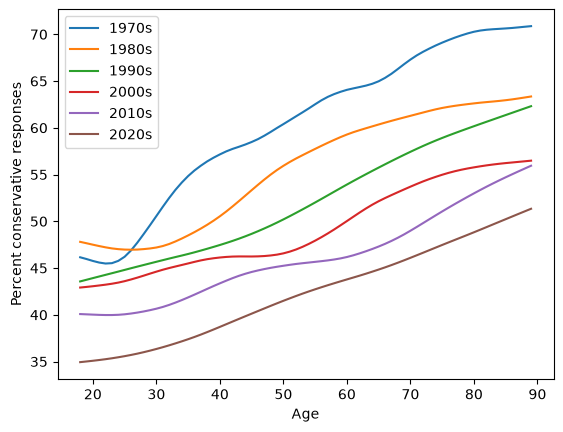

In [43]:
for start, (curve, _, _) in age_fits.items():
    plt.plot(curve["age"], curve["mean"], label=f"{start}s")
plt.xlabel("Age")
plt.ylabel("Percent conservative responses")
plt.legend();

The slope of each curve, in percentage points per decade of age, compared with the production fits:

In [44]:
windows = {1970: "1972-1979", 1980: "1980-1989", 1990: "1990-1999", 2000: "2000-2009", 2010: "2010-2019",
           2020: "2020-2024"}
pd.DataFrame({f"{start}s": dict(here=s["slope_per_decade"],
                                production=saved.loc[f"age_primary_window-{windows[start]}", "slope_per_decade"])
              for start, (_, s, _) in age_fits.items()}).T.round(2)

,here,production
1970s,3.86,3.87
1980s,2.86,2.86
1990s,2.86,2.86
2000s,2.18,2.18
2010s,2.25,2.25
2020s,2.41,2.41


### Conservatism by self-identified ideology

NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


NUTS[nutpie]: [alpha, sigma_t, trend_w, trend_trend, sigma_short, epsilon_z]


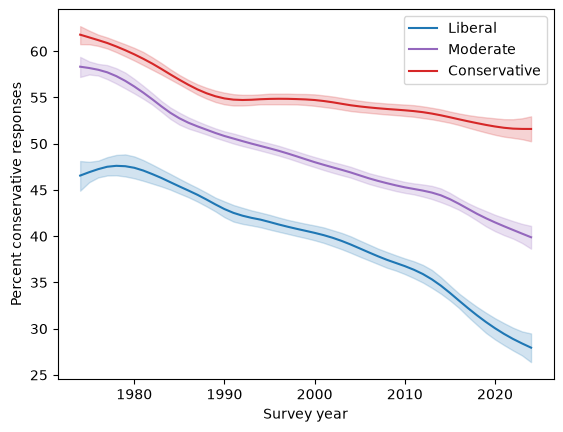

In [45]:
group_fits = {g: fit_series(df[df["polviews3"] == g], "year") for g in ["Liberal", "Moderate", "Conservative"]}
for g, color in zip(group_fits, ["C0", "C4", "C3"]):
    curve = group_fits[g][0]
    plt.plot(curve["year"], curve["mean"], color=color, label=g)
    plt.fill_between(curve["year"], curve["lo90"], curve["hi90"], color=color, alpha=0.2)
plt.xlabel("Survey year")
plt.ylabel("Percent conservative responses")
plt.legend();

### Change within cohorts

In [46]:
period_df, cohort_df, pc_summary, pc_trace = fit_period_cohort(df)

NUTS[nutpie]: [alpha, sigma_c, cohort_w, cohort_trend, sigma_t, period_w, period_trend, sigma_short, epsilon_z, sigma_resid]


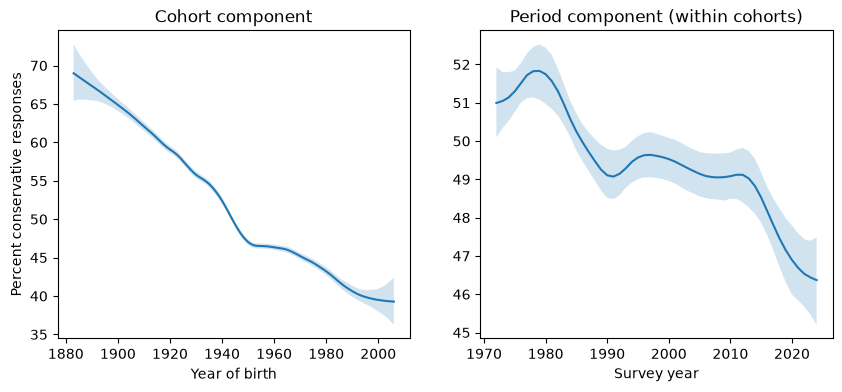

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, comp, x, label in [(axes[0], cohort_df, "cohort", "Year of birth"), (axes[1], period_df, "year", "Survey year")]:
    ax.plot(comp[x], comp["mean"])
    ax.fill_between(comp[x], comp["lo90"], comp["hi90"], alpha=0.2)
    ax.set_xlabel(label)
axes[0].set_ylabel("Percent conservative responses")
axes[0].set_title("Cohort component")
axes[1].set_title("Period component (within cohorts)");

The within-cohort slope and the decomposition, compared with the production fit:

In [48]:
keys = ["period_slope_per_decade", "period_slope_lo90", "period_slope_hi90", "total_change",
        "generational_replacement", "changing_minds"]
pd.DataFrame(dict(here=[pc_summary[k] for k in keys],
                  production=saved.loc["period_cohort_primary", keys].astype(float))).round(2)

,here,production
period_slope_per_decade,-0.81,-0.82
period_slope_lo90,-0.97,-0.97
period_slope_hi90,-0.66,-0.66
total_change,-16.39,-16.40
generational_replacement,-11.81,-11.80
changing_minds,-4.58,-4.60


### By decade of birth

The same period–cohort model, fit separately within each decade of birth, shows whether every group follows the same pattern. These fits are loaded from the production results.

In [49]:
groups = saved[(saved["model"] == "period_cohort") & (saved["set"] == "primary") & saved["cohorts"].notna()]
decades = groups[groups["cohorts"].str.match(r"^\d{3}0-\d{3}9$")]
decades.set_index("cohorts")[["period_slope_per_decade", "period_slope_lo90", "period_slope_hi90",
                               "respondents"]].round(2)

,period_slope_per_decade,period_slope_lo90,period_slope_hi90,respondents
cohorts,,,,
1900-1909,-2.54,-3.93,-1.14,2050
1910-1919,-2.30,-2.93,-1.67,4093
1920-1929,-1.10,-1.65,-0.49,5914
1930-1939,-0.97,-1.31,-0.63,6841
1940-1949,-0.52,-0.77,-0.28,10481
1950-1959,-0.19,-0.45,0.08,13248
1960-1969,-0.75,-1.12,-0.38,9839
1970-1979,-0.45,-1.12,0.27,6099
1980-1989,-2.36,-3.60,-1.13,3730


## Relative position

The Overton paradox is about relative position: a liberal of the 1970s would be right of center today. To measure it, I estimate the distribution of latent conservatism in each group of respondents (each survey year, and each year × self-identified ideology), and express a position as a percentile of a year's distribution.

The distributions are normal on the logit scale, estimated by weighted EM on a fine grid with the difficulties held fixed. Unlike the individual scores, they aren't widened by measurement noise or pulled toward the prior, so their spread doesn't depend on how many questions people answered. Positions are medians, so the percentiles are the same on any monotone scale.

In [50]:
XS_FINE = np.linspace(-6, 6, 121)
GROUPS = ["Liberal", "Moderate", "Conservative"]
LAST_YEAR = 2024


def latent_normals(answers, weights, d, groups, tol=1e-6, max_iter=500):
    """Mean and SD of a normal latent distribution in each group, difficulties fixed."""
    w = np.asarray(weights, dtype=float)
    labels, codes = np.unique(np.asarray(groups), return_inverse=True)
    loglike = log_likelihoods(answers, d, XS_FINE).sum(axis=0)
    like = np.exp(loglike - loglike.max(axis=1, keepdims=True))
    mu, sd = np.zeros(len(labels)), np.ones(len(labels))
    for _ in range(max_iter):
        posterior = like * norm.pdf(XS_FINE[None, :], mu[:, None], sd[:, None])[codes]
        posterior /= posterior.sum(axis=1, keepdims=True)
        total = np.stack([w[codes == k] @ posterior[codes == k] for k in range(len(labels))])
        m1 = total @ XS_FINE / total.sum(axis=1)
        m2 = total @ XS_FINE**2 / total.sum(axis=1)
        new_sd = np.sqrt(m2 - m1**2)
        change = max(np.abs(m1 - mu).max(), np.abs(new_sd - sd).max())
        mu, sd = m1, new_sd
        if change < tol:
            break
    return pd.DataFrame(dict(mu=mu, sd=sd), index=labels)


answers = coded.loc[keep, primary].values
dfp = df.reset_index(drop=True)
in_groups = dfp["polviews3"].isin(GROUPS).values
by_year = latent_normals(answers, dfp["weight"], d_primary.values, dfp["year"].astype(str))
by_group = latent_normals(answers[in_groups], dfp.loc[in_groups, "weight"], d_primary.values,
                          dfp.loc[in_groups, "year"].astype(str) + "|" + dfp.loc[in_groups, "polviews3"])

The reference point is the median liberal of 1974, the first year with enough self-identified liberals among the scored respondents. In each year, its percentile is the share of that year's distribution below it.

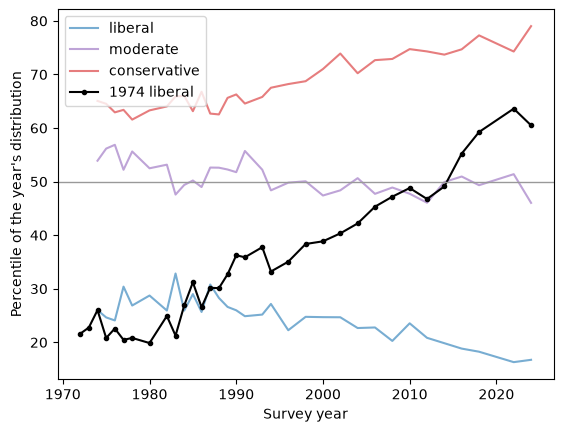

In [51]:
REF_YEAR = 1974
ref = by_group.loc[f"{REF_YEAR}|Liberal", "mu"]
rows = []
for y in sorted(dfp["year"].unique()):
    dist = by_year.loc[str(y)]
    row = dict(year=y, ref_liberal=100 * norm.cdf(ref, dist["mu"], dist["sd"]))
    for g in GROUPS:
        if f"{y}|{g}" in by_group.index:
            row[g.lower()] = 100 * norm.cdf(by_group.loc[f"{y}|{g}", "mu"], dist["mu"], dist["sd"])
    rows.append(row)
position = pd.DataFrame(rows).set_index("year")

position[["liberal", "moderate", "conservative"]].plot(alpha=0.6, color=["C0", "C4", "C3"])
plt.plot(position.index, position["ref_liberal"], "ko-", ms=3, label=f"{REF_YEAR} liberal")
plt.axhline(50, color="0.6", lw=1)
plt.ylabel("Percentile of the year's distribution")
plt.xlabel("Survey year")
plt.legend();

In 2024, with 90% intervals from a bootstrap of respondents in the two years involved (the bootstrap ignores the GSS's clustered design, so the intervals are somewhat too narrow):

In [52]:
def headline_numbers(sub, sub_answers):
    in_g = sub["polviews3"].isin(GROUPS).values
    year = latent_normals(sub_answers, sub["weight"], d_primary.values, sub["year"].astype(str)).loc[str(LAST_YEAR)]
    grp = latent_normals(sub_answers[in_g], sub.loc[in_g, "weight"], d_primary.values,
                         sub.loc[in_g, "year"].astype(str) + "|" + sub.loc[in_g, "polviews3"])
    out = dict(ref_liberal=100 * norm.cdf(grp.loc[f"{REF_YEAR}|Liberal", "mu"], year["mu"], year["sd"]))
    for g in GROUPS:
        out[g.lower()] = 100 * norm.cdf(grp.loc[f"{LAST_YEAR}|{g}", "mu"], year["mu"], year["sd"])
    return out


two = dfp["year"].isin([REF_YEAR, LAST_YEAR]).values
sub, sub_answers = dfp[two].reset_index(drop=True), answers[two]
point = headline_numbers(sub, sub_answers)
rng = np.random.default_rng(17)
draws = []
for _ in range(200):
    rows = np.concatenate([rng.choice(idx, len(idx)) for idx in sub.groupby("year").indices.values()])
    draws.append(headline_numbers(sub.iloc[rows].reset_index(drop=True), sub_answers[rows]))
draws = pd.DataFrame(draws)
pd.DataFrame(dict(percentile=point, lo90=draws.quantile(0.05), hi90=draws.quantile(0.95))).round(1)

,percentile,lo90,hi90
ref_liberal,60.5,54.9,65.5
liberal,16.7,13.8,19.3
moderate,46.0,42.5,49.9
conservative,79.0,76.7,81.2


Check, against the production results:

In [53]:
saved_headline = pd.read_csv(download("position_headline.csv")).set_index("set").loc["primary"]
assert all(abs(point[k] - saved_headline[k]) < 1e-6 for k in point)

## Sensitivity

How much do the choices matter? These comparisons were run after the choices were made, and reported whatever they showed; they weren't used to choose. All are production fits, loaded:

- **primary**: the decided specification, 53 questions;
- **with_confidence**: the same, keeping the confidence questions that pass the stability rule (65 questions);
- **p48**: the previous selection, 48 questions, under the earlier stability rule (which also excluded questions whose gap faded);
- **social** and **econA**: the social questions and the core economic questions among the primary questions.

In [54]:
rows = {}
for name in ["primary", "with_confidence", "p48", "social", "econA"]:
    run = saved.loc[f"period_cohort_{name}"]
    rows[name] = run[["n_questions", "respondents", "period_slope_per_decade", "period_slope_lo90",
                      "period_slope_hi90", "generational_replacement", "changing_minds"]]
pd.DataFrame(rows).T.round(2)

,n_questions,respondents,period_slope_per_decade,period_slope_lo90,period_slope_hi90,generational_replacement,changing_minds
primary,53,64632,-0.815181,-0.969461,-0.662761,-11.804797,-4.59719
with_confidence,65,64633,-0.012609,-0.22972,0.200917,-10.601438,-0.404731
p48,48,64610,-0.843334,-1.00657,-0.681719,-12.038598,-4.924553
social,36,63233,-1.162354,-1.344668,-0.978108,-14.339167,-6.335697
econA,4,35141,1.613831,1.164419,2.074857,-8.782266,3.713437


## Diagnostics

Every production fit, with its largest R-hat, smallest bulk effective sample size, and number of divergent transitions:

In [55]:
diag = saved[saved["set"].isin(["primary", "with_confidence", "social", "econA"])]
diag[["model", "set", "by", "window", "cohorts", "target_accept", "rhat_max", "ess_bulk_min", "divergences"]]

,model,set,by,window,cohorts,target_accept,rhat_max,ess_bulk_min,divergences
run,,,,,,,,,
age_primary_cohorts-1883-1927,age,primary,NaN,NaN,1883-1927,0.99,1.000868,5004.797815,0
age_primary_cohorts-1900-1909,age,primary,NaN,NaN,1900-1909,0.99,1.000764,4554.239275,0
age_primary_cohorts-1910-1919,age,primary,NaN,NaN,1910-1919,0.99,1.002195,3455.346542,0
age_primary_cohorts-1920-1929,age,primary,NaN,NaN,1920-1929,0.99,1.000563,4377.330892,0
age_primary_cohorts-1928-1945,age,primary,NaN,NaN,1928-1945,0.99,1.000658,5377.472420,0
...,...,...,...,...,...,...,...,...,...
period_social_polviews3-Moderate,period,social,polviews3=Moderate,NaN,NaN,0.99,1.001760,3187.204498,0
period_social,period,social,NaN,NaN,NaN,0.99,1.002417,1408.204891,1
period_with_confidence_polviews3-Conservative,period,with_confidence,polviews3=Conservative,NaN,NaN,0.99,1.002811,2197.967452,0


In [56]:
pd.Series(dict(rhat_max=diag["rhat_max"].max(), ess_bulk_min=diag["ess_bulk_min"].min(),
           divergences=diag["divergences"].sum(), fits_with_divergences=(diag["divergences"] > 0).sum())).round(3)

rhat_max                   1.009
ess_bulk_min             809.914
divergences              597.000
fits_with_divergences     20.000
dtype: float64

And the fits in this notebook. With shorter runs, the effective sample sizes are smaller, but the estimates agree with the production fits, as shown above:

In [57]:
import arviz as az

rows = {}
for label, trace in [("period-cohort", pc_trace)] + [(f"period {g}", t) for g, (_, _, t) in group_fits.items()] + \
        [(f"age {s}s", t) for s, (_, _, t) in age_fits.items()]:
    summary = az.summary(trace, var_names=["alpha", "sigma_t", "sigma_short"], kind="diagnostics")
    rows[label] = dict(rhat_max=summary["r_hat"].max(), ess_bulk_min=summary["ess_bulk"].min(),
                       divergences=int(trace.sample_stats["diverging"].values.sum()))
pd.DataFrame(rows).T

,rhat_max,ess_bulk_min,divergences
period-cohort,1.03,133,0
period Liberal,1.00,194,0
period Moderate,1.02,96,0
period Conservative,1.00,333,0
age 1970s,1.00,359,0
age 1980s,1.01,322,0
age 1990s,1.01,465,0
age 2000s,1.01,368,0
age 2010s,1.01,241,0
age 2020s,1.00,420,0
